# Block 3 — ML risk model: evaluation (Member 4)

*Educational simulation only. No real medical diagnosis or treatment recommendation.*

This notebook only **reads** the results written by the scripts and exports the report figures, so it stays
in sync with the code:

```bash
python -m er_agent.learning.data_gen --seed 42      # data/tabular.csv, data/temporal.npz
python -m er_agent.learning.ml.train                # models/ml_rf.joblib, experiments/ml/results.*
python -m er_agent.learning.ml.real_eval            # bonus, real KTAS data -> experiments/ml/real_results.*
```
Set `RERUN = True` below to run them from here (≈ 6 min).

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, Markdown, display
from er_agent.learning import data_gen
from er_agent.learning.data_gen import CLASSES

RERUN = False
if RERUN:
    from er_agent.learning.ml import train, real_eval
    data_gen.generate(seed=42)
    train.run(data_gen.DATA_DIR / "tabular.csv")
    real_eval.run()
res = json.loads(Path("experiments/ml/results.json").read_text())
real = json.loads(Path("experiments/ml/real_results.json").read_text())
pd.set_option("display.precision", 3)

## 1. Dataset

In [2]:
tab = pd.read_csv(data_gen.DATA_DIR / "tabular.csv")
display(tab.head())
display(tab.risk.value_counts(normalize=True).reindex(CLASSES).rename("share").to_frame().T)
tab.describe().T[["mean", "std", "min", "50%", "max"]]

,age,hr,sbp,dbp,spo2,temp,rr,chest_pain,sob,abdominal_pain,fever_symptom,consciousness,noise_uniform,noise_gauss,risk
0,81,30,132,74,93,38.3,11,0,0,1,0,alert,0.696,0.256,High
1,43,71,129,83,91,37.2,20,0,0,0,0,alert,0.982,0.422,Low
2,67,109,130,80,95,37.2,20,0,0,0,0,alert,0.471,2.528,Low
3,54,77,118,80,97,37.7,17,0,0,0,0,alert,0.978,0.735,Low
4,74,105,132,85,96,37.9,20,1,1,0,0,alert,0.807,1.186,High


risk,Low,Medium,High,Critical
share,0.485,0.329,0.132,0.054


,mean,std,min,50%,max
age,53.337,18.606,18.000,53.000,98.000
hr,91.417,18.993,30.000,90.000,188.000
sbp,116.907,17.800,55.000,118.000,182.000
dbp,74.145,12.820,30.000,74.000,129.000
spo2,95.519,2.478,83.000,96.000,100.000
temp,37.188,0.740,35.700,37.000,42.000
rr,17.745,3.501,7.000,17.000,35.000
chest_pain,0.163,0.369,0.000,0.000,1.000
sob,0.180,0.384,0.000,0.000,1.000
abdominal_pain,0.182,0.386,0.000,0.000,1.000


In [3]:
import numpy as np
seq = np.load(data_gen.DATA_DIR / "temporal.npz")
y, pid = seq["y"], seq["pair_id"]
pairs = [np.flatnonzero(pid == k) for k in range(pid.max() + 1)]
print("temporal X", seq["X"].shape, "| lengths", seq["lengths"].min(), "-", seq["lengths"].max())
print("trajectory types:", dict(zip(seq["traj_names"], np.bincount(seq["traj_type"]))))
print(f"pairs with identical last step: {len(pairs)}, different label: {np.mean([y[a] != y[b] for a, b in pairs]):.1%}")

temporal X (4000, 12, 5) | lengths 5 - 12
trajectory types: {np.str_('stable'): np.int64(1137), np.str_('noisy_stable'): np.int64(482), np.str_('slow_det'): np.int64(885), np.str_('fast_det'): np.int64(535), np.str_('recovery'): np.int64(961)}
pairs with identical last step: 400, different label: 87.8%


## 2. Feature selection
Kept iff mutual information **and** permutation importance beat both pure-noise columns. RF impurity importance is shown to illustrate its bias towards continuous features.

In [4]:
pd.DataFrame(res["feature_selection"]).set_index("feature")

,mutual_info,perm_importance,perm_std,rf_impurity,spearman_vs_risk,kept
feature,,,,,,
rr,0.213,0.125,0.011,0.148,4.612e-01,True
sbp,0.150,0.105,0.010,0.138,-4.636e-01,True
spo2,0.214,0.099,0.005,0.129,-5.224e-01,True
chest_pain,0.053,0.070,0.009,0.055,3.194e-01,True
hr,0.193,0.069,0.006,0.142,4.749e-01,True
age,0.041,0.035,0.007,0.079,2.428e-01,True
temp,0.026,0.027,0.005,0.060,1.744e-01,True
sob,0.056,0.020,0.006,0.034,3.154e-01,True
fever_symptom,0.026,0.017,0.003,0.016,2.272e-01,True


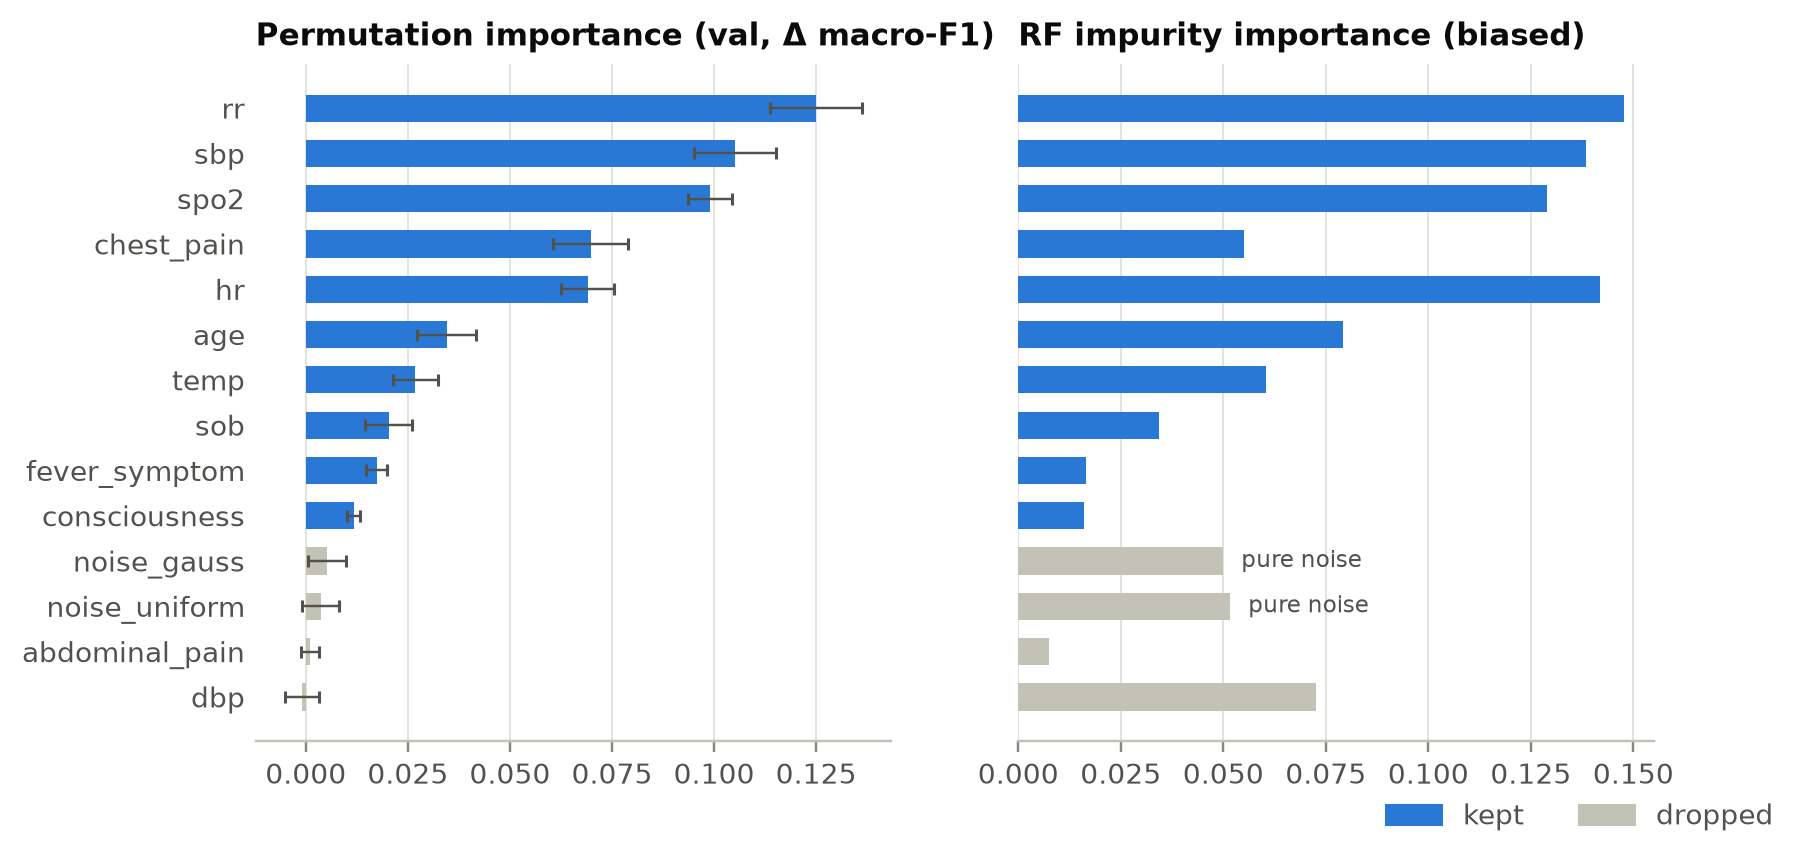

In [5]:
from er_agent.learning.ml import figures
paths = {p.stem: p for p in figures.make_all()}
display(Image(paths["ml_feature_importance"]))

## 3. Model comparison (validation split)

,model,class_weight,acc,macro_F1,recall_Critical,ECE,train_F1,gap
0,DecisionTree,none,0.672,0.601,0.492,0.053,0.692,0.092
1,DecisionTree,balanced,0.673,0.629,0.646,0.070,0.675,0.046
2,RandomForest,none,0.744,0.684,0.492,0.049,0.891,0.208
3,RandomForest,balanced,0.748,0.725,0.692,0.076,0.902,0.177
4,LogisticRegression,none,0.733,0.709,0.615,0.049,0.711,0.002
5,LogisticRegression,balanced,0.703,0.697,0.769,0.074,0.693,-0.003
6,HistGradientBoosting,none,0.746,0.701,0.554,0.074,0.981,0.280
7,HistGradientBoosting,balanced,0.740,0.703,0.569,0.074,0.976,0.273


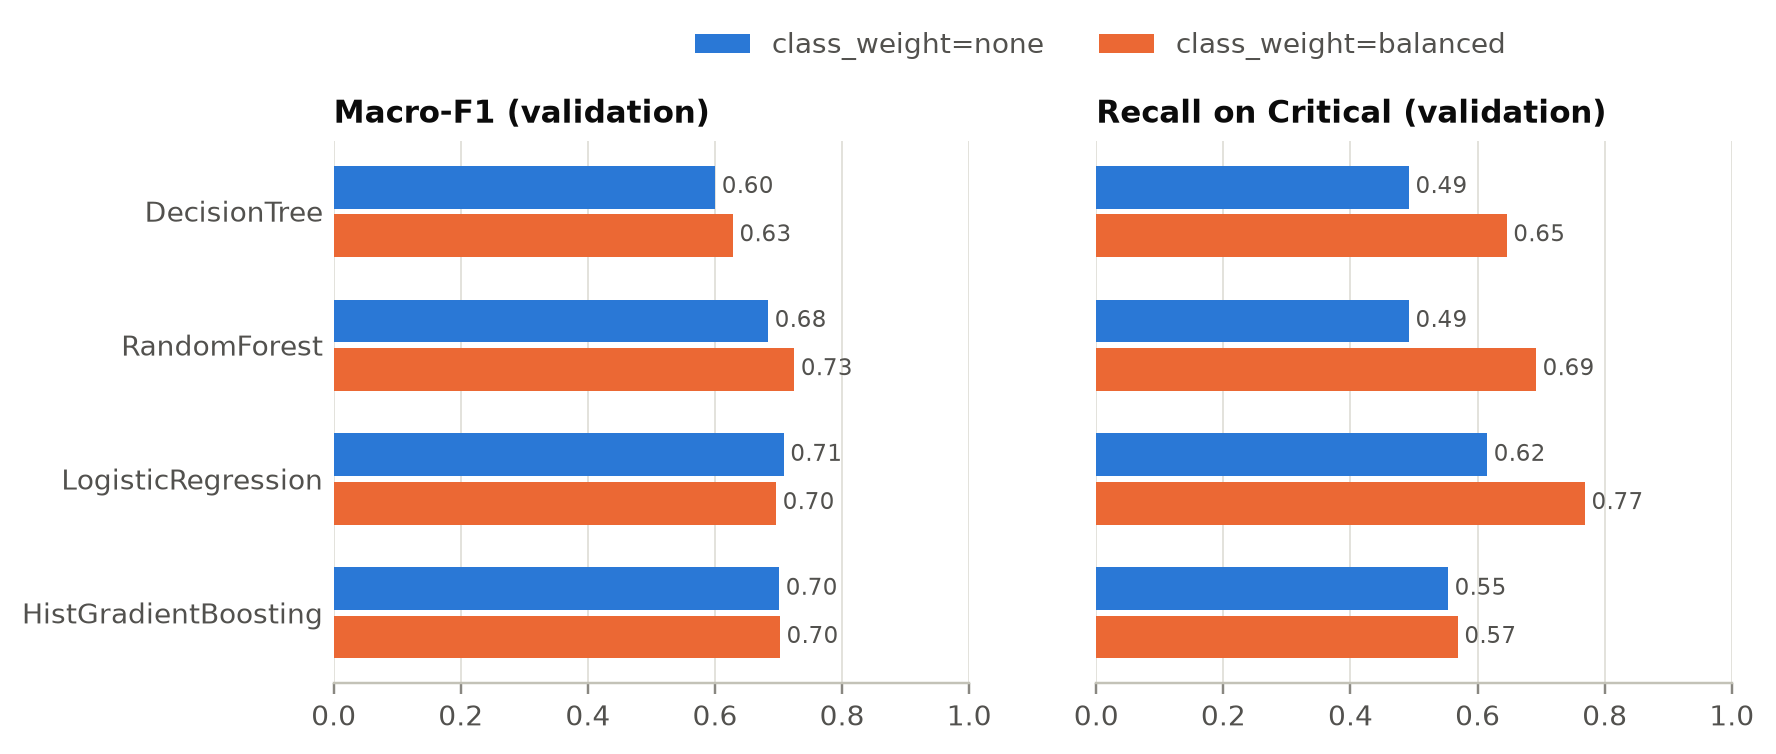

RF grid search: {'best_params': {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 14, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}, 'cv_macro_f1': 0.734537505090904, 'n_candidates': 54}


In [6]:
rows = []
for k, d in res["comparison"].items():
    m, cw = k.split("|"); v = d["val"]
    rows.append({"model": m, "class_weight": cw, "acc": v["accuracy"], "macro_F1": v["macro_f1"],
                 "recall_Critical": v["recall"]["Critical"], "ECE": v["ece"],
                 "train_F1": d["train"]["macro_f1"], "gap": d["train"]["macro_f1"] - v["macro_f1"]})
display(pd.DataFrame(rows))
display(Image(paths["ml_model_comparison"]))
print("RF grid search:", res["grid_search"])

## 4. Calibration
The KB uses `p ≥ 0.7` thresholds, so probabilities must mean what they say.

,ece,brier,macro_f1
uncalibrated,0.078,0.361,0.731
sigmoid,0.025,0.352,0.716
isotonic,0.028,0.352,0.729


chosen: isotonic


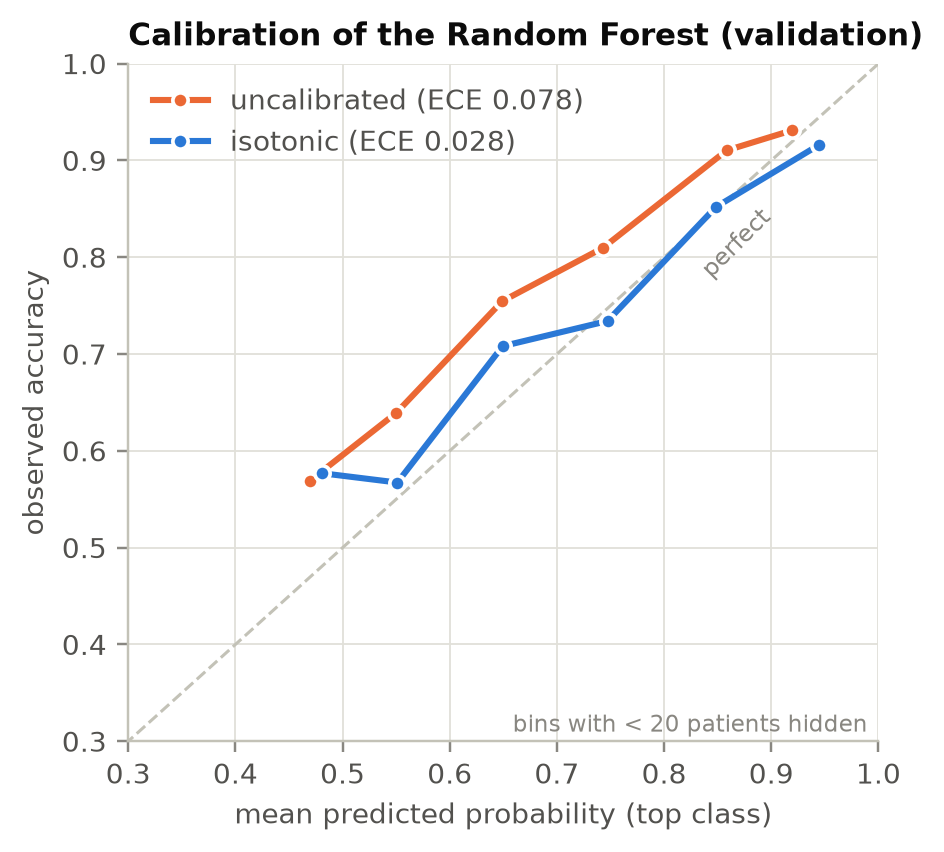

In [7]:
display(pd.DataFrame({k: {m: v[m] for m in ("ece", "brier", "macro_f1")} for k, v in res["calibration_val"].items()}).T)
print("chosen:", res["calibration_chosen"])
display(Image(paths["ml_reliability"]))

## 5. Deployed model — test split (looked at once)

,Low,Medium,High,Critical
recall,0.808,0.706,0.646,0.692
F1,0.827,0.671,0.658,0.738


test acc 0.747  macro-F1 0.723  | train macro-F1 0.890 (overfitting gap 0.167)


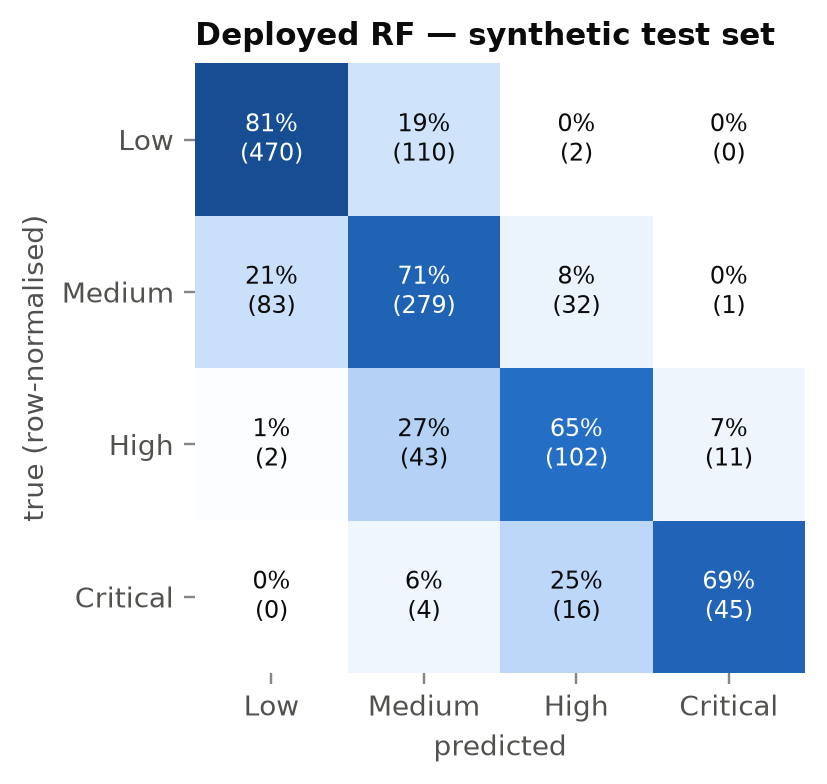

In [8]:
t, tr = res["deployed"]["test"], res["deployed"]["train"]
display(pd.DataFrame({"recall": t["recall"], "F1": t["f1"]}).T)
print(f"test acc {t['accuracy']:.3f}  macro-F1 {t['macro_f1']:.3f}  | train macro-F1 {tr['macro_f1']:.3f} (overfitting gap {tr['macro_f1'] - t['macro_f1']:.3f})")
display(Image(paths["ml_confusion"]))

## 6. Integration — `predict_ml` on the brief's patients

In [9]:
from er_agent.learning.ml import ml_risk_fact, predict_proba_ml
base = json.loads(Path("scenarios/base_example.json").read_text())
pd.DataFrame([{"fact": ml_risk_fact(p), **{c: round(v, 3) for c, v in predict_proba_ml(p).items()},
               "expected (fused)": base["expected"][p["id"]]["risk"]} for p in base["patients"]])

,fact,Low,Medium,High,Critical,expected (fused)
0,"(ML_Risk, P1, Critical, 0.992)",0.001,0.000,0.007,0.992,Critical
1,"(ML_Risk, P2, Low, 0.55)",0.550,0.431,0.014,0.004,Medium
2,"(ML_Risk, P3, Low, 0.957)",0.957,0.040,0.000,0.004,Low


## 7. Bonus — real triage data (KTAS, Moon et al. 2019, CC BY 4.0)

In [10]:
Markdown(Path("experiments/ml/real_results.md").read_text().split("## Why")[0])

# Real-data evaluation — KTAS (Moon et al. 2019, PLOS ONE, CC BY 4.0)

Auto-generated by `python -m er_agent.learning.ml.real_eval`. Label = expert KTAS mapped 1→Critical, 2→High, 3→Medium, 4/5→Low. 1267 adult ED visits, two Korean hospitals.

- class distribution real: {'Low': 0.4215, 'Medium': 0.3844, 'High': 0.1736, 'Critical': 0.0205}
- class distribution synthetic: {'Low': 0.485, 'Medium': 0.329, 'High': 0.1319, 'Critical': 0.0541}
- missing rate per vital (real): {'hr': 0.016, 'sbp': 0.02, 'dbp': 0.023, 'spo2': 0.55, 'temp': 0.014, 'rr': 0.017}
- admitted / ICU / died: 30.8%
- shared features (= deployed model): `['age', 'hr', 'sbp', 'spo2', 'temp', 'rr', 'chest_pain', 'sob', 'fever_symptom', 'consciousness']`
- full features: `['age', 'hr', 'sbp', 'spo2', 'temp', 'rr', 'chest_pain', 'sob', 'fever_symptom', 'consciousness', 'dbp', 'nrs_pain', 'injury', 'arrival_ambulance', 'mental_level']` + missing-value indicators

## Results

| experiment | acc | macro-F1 [95% CI] | recall Critical [95% CI] | recall L / M / H | ECE | AUROC admission |
|---|---|---|---|---|---|---|
| H — triage nurse vs expert (human reference) | 0.875 | 0.823 [0.77, 0.86] | 0.58 [0.39, 0.75] | 0.96 / 0.82 / 0.83 | — | 0.704 |
| B — deployed synthetic model, no retraining | 0.472 | 0.326 [0.27, 0.37] | 0.15 [0.03, 0.31] | 0.88 / 0.21 / 0.11 | 0.319 | 0.636 |
| A — Decision Tree, real CV, shared features | 0.490 | 0.460 [0.42, 0.50] | 0.68 [0.47, 0.84] | 0.52 / 0.45 / 0.48 | 0.073 | 0.627 |
| A — Logistic Regression, real CV, shared | 0.506 | 0.470 [0.43, 0.51] | 0.85 [0.68, 0.96] | 0.62 / 0.40 / 0.42 | 0.068 | 0.664 |
| A — Random Forest, real CV, shared | 0.549 | 0.543 [0.48, 0.58] | 0.64 [0.43, 0.81] | 0.67 / 0.42 / 0.55 | 0.035 | 0.670 |
| A — Decision Tree, real CV, full features | 0.551 | 0.514 [0.46, 0.54] | 0.71 [0.42, 0.81] | 0.67 / 0.41 / 0.56 | 0.053 | 0.661 |
| A — Logistic Regression, real CV, full | 0.563 | 0.571 [0.52, 0.62] | 0.68 [0.45, 0.83] | 0.59 / 0.49 / 0.64 | 0.044 | 0.704 |
| A — Random Forest, real CV, full | 0.669 | 0.668 [0.61, 0.70] | 0.78 [0.59, 0.92] | 0.69 / 0.66 / 0.63 | 0.088 | 0.695 |
| C — RF synthetic + real, shared | 0.533 | 0.546 [0.49, 0.59] | 0.56 [0.34, 0.73] | 0.71 / 0.35 / 0.49 | 0.064 | 0.656 |
| C — RF synthetic + real (re-weighted), shared | 0.531 | 0.538 [0.50, 0.58] | 0.59 [0.47, 0.85] | 0.66 / 0.38 / 0.55 | 0.062 | 0.652 |

Reference: the expert KTAS itself has AUROC 0.699 for admission.

A/C: mean over 3 repeats of stratified 5-fold CV; CIs and AUROC from the first repeat's pooled out-of-fold predictions. Only 26 Critical patients → Critical recall CIs are wide.



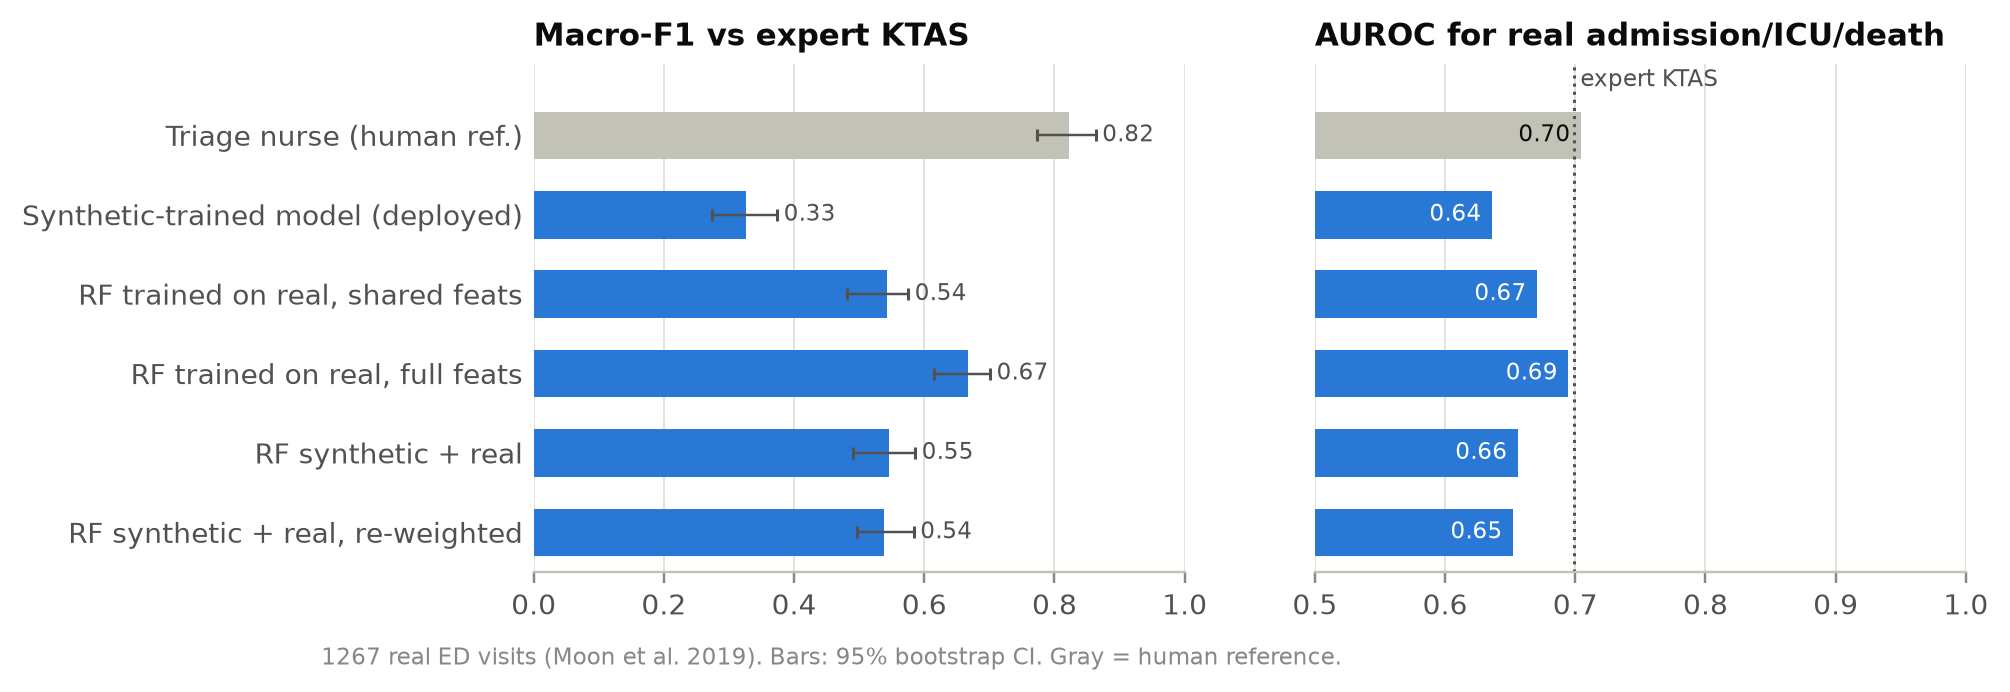

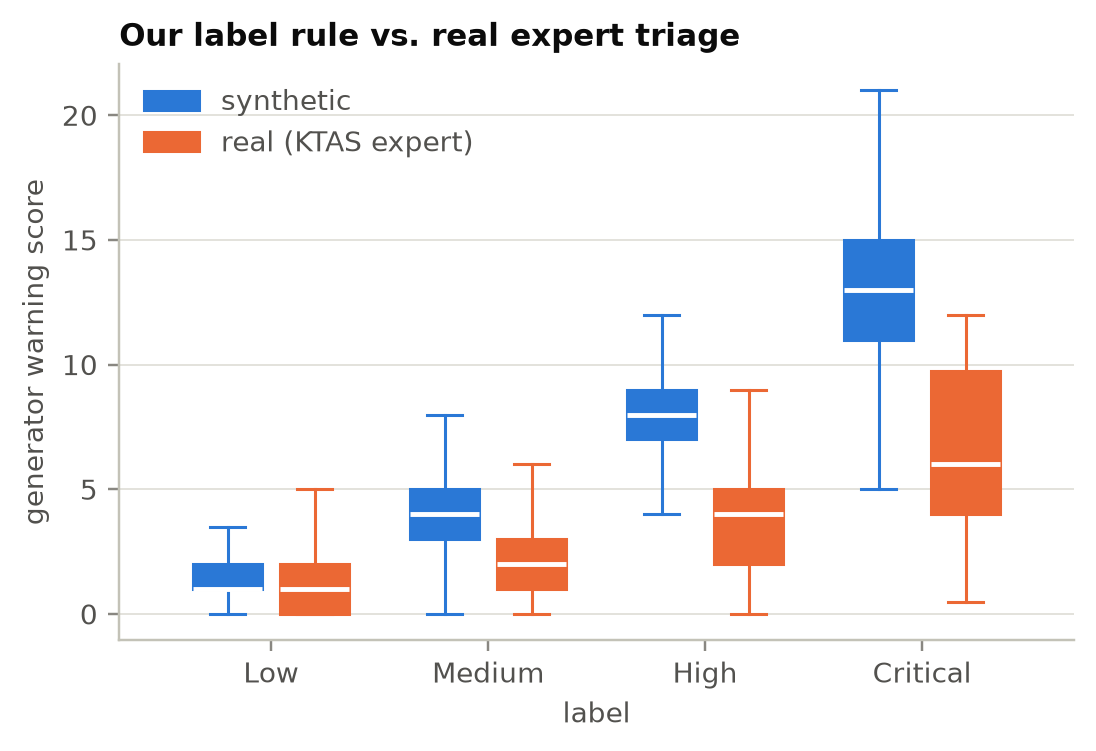

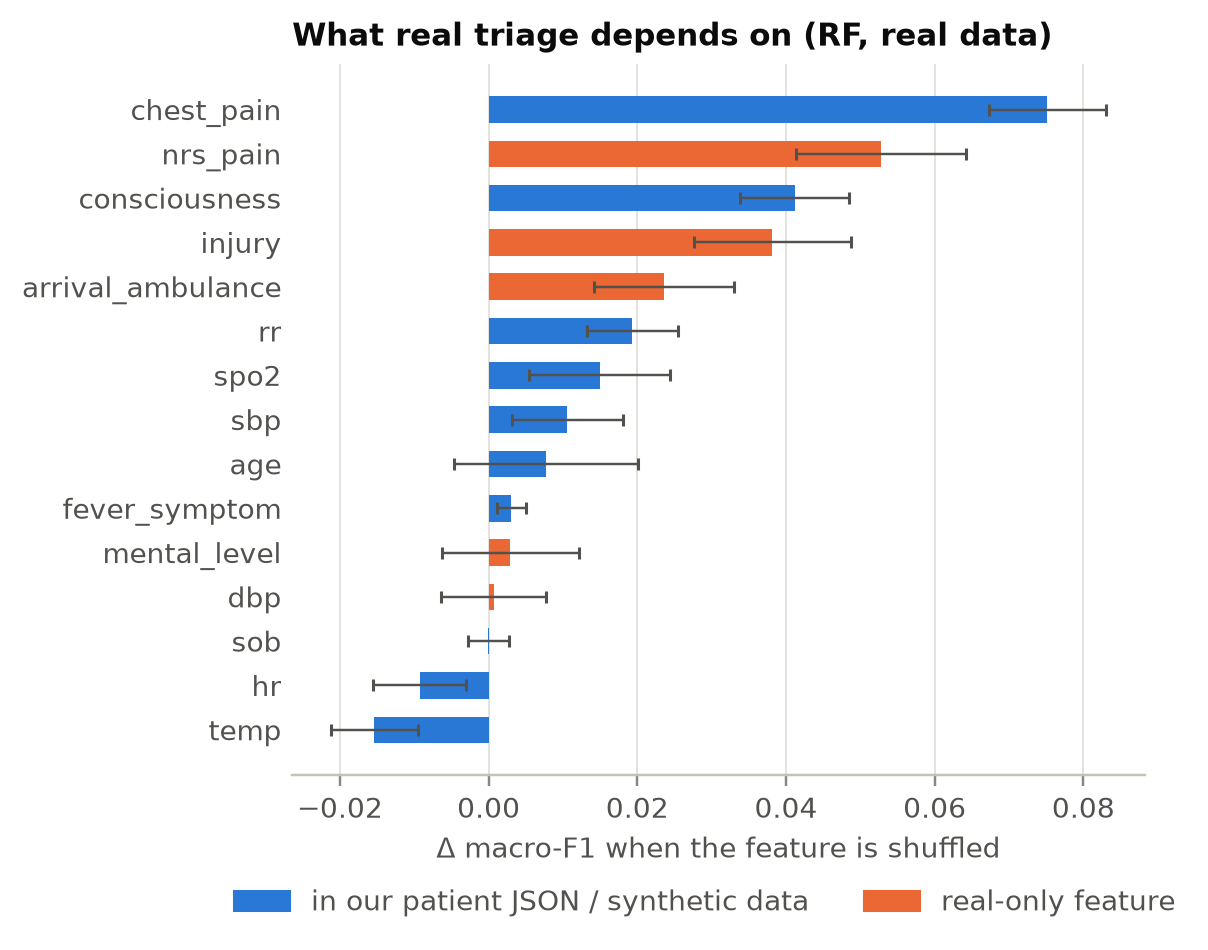

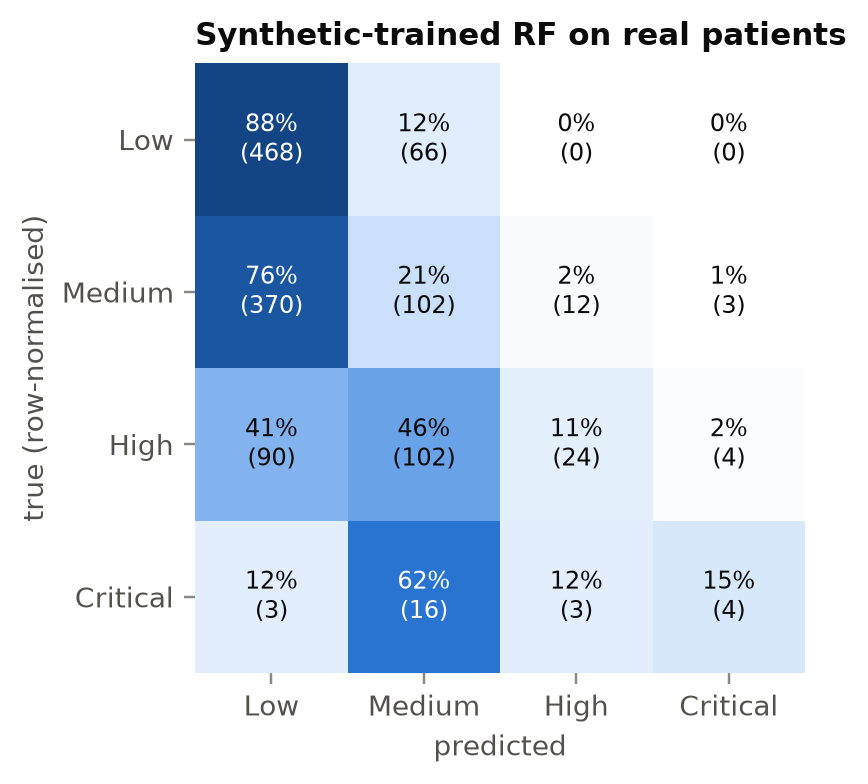

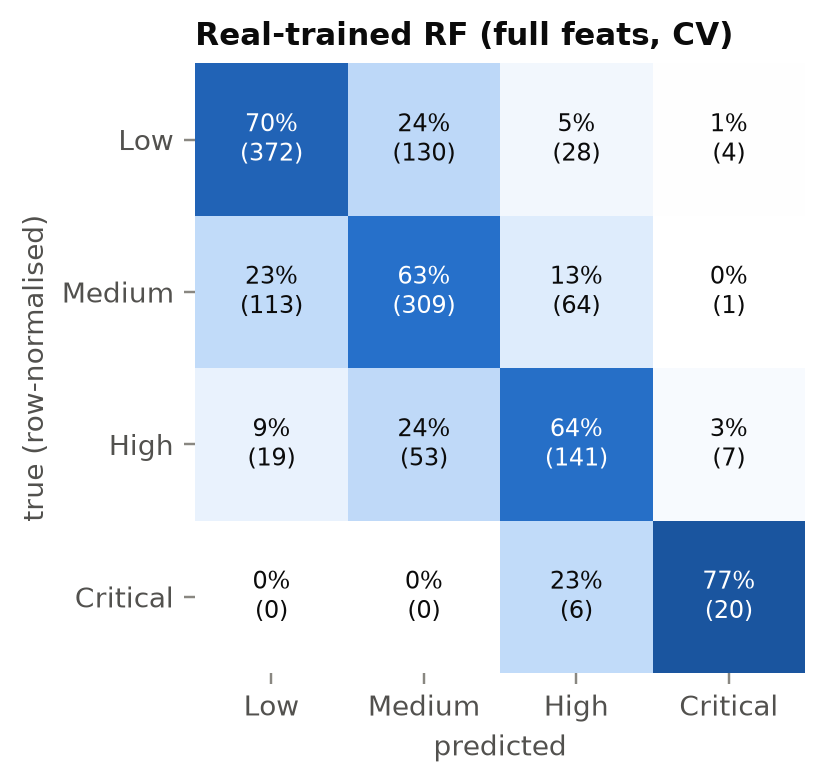

In [11]:
display(Image(paths["ml_real_transfer"]))
display(Image(paths["ml_real_generator_score"]))
display(Image(paths["ml_real_importance"]))
display(Image(paths["ml_real_confusion_synthetic"])); display(Image(paths["ml_real_confusion_real"]))

## 8. Bonus — decision tree → Horn rules for the KB
Trees on the discretized World facts; negative branches dropped (Horn), kept iff val precision ≥ 0.7, 95% Wilson lower bound ≥ 0.6, support ≥ 20. Regenerate with `python -m er_agent.learning.ml.rules_export`.

In [12]:
from er_agent.learning.ml.rules_export import load_learned_rules
for name, prem, concl in load_learned_rules():
    print(f"{name}: {' ∧ '.join(f'{p[0]}({chr(44).join(p[1:])})' for p in prem)} → {concl[0]}({concl[1]})")
Markdown(Path("experiments/ml/rules_results.md").read_text().split("\n", 2)[2])

Learned_R1: HasSymptom(?x,ChestPain) ∧ Tachycardia(?x) → HighRisk(?x)
Learned_R2: HasSymptom(?x,ShortnessOfBreath) ∧ Tachycardia(?x) → HighRisk(?x)
Learned_R3: Tachypnea(?x) → HighRisk(?x)
Learned_R4: LowBloodPressure(?x) → HighRisk(?x)
Learned_R5: HasSymptom(?x,ChestPain) ∧ HasSymptom(?x,ShortnessOfBreath) → HighRisk(?x)


Kept iff validation precision ≥ 0.7, its 95% Wilson lower bound ≥ 0.6 and support ≥ 20 (tree depth 5).

| rule | val precision [lower 95%] | val support | val recall | test precision |
|---|---|---|---|---|
| `Learned_R1: HasSymptom(?x, ChestPain) ∧ Tachycardia(?x) → HighRisk(?x)` | 0.87 [0.73] | 38 | 0.15 | 0.87 |
| `Learned_R2: HasSymptom(?x, ShortnessOfBreath) ∧ Tachycardia(?x) → HighRisk(?x)` | 0.86 [0.74] | 51 | 0.20 | 0.82 |
| `Learned_R3: Tachypnea(?x) → HighRisk(?x)` | 0.86 [0.76] | 72 | 0.28 | 0.85 |
| `Learned_R4: LowBloodPressure(?x) → HighRisk(?x)` | 0.82 [0.71] | 67 | 0.25 | 0.78 |
| `Learned_R5: HasSymptom(?x, ChestPain) ∧ HasSymptom(?x, ShortnessOfBreath) → HighRisk(?x)` | 0.82 [0.68] | 44 | 0.16 | 0.80 |

No CriticalRisk rule passes the filter: on binary facts alone, Critical cannot be isolated reliably by a short rule. CriticalRisk stays derived from DL_Risk / ML_Risk (R5) and R6.

## Rule sets as classifiers (test split, forward chaining to fixpoint)

| rule set | HighRisk P | HighRisk R | CriticalRisk P | CriticalRisk R |
|---|---|---|---|---|
| learned rules | 0.74 | 0.67 | 0.00 | 0.00 |
| hand-written R1, R2, R6 | 0.92 | 0.15 | 1.00 | 0.18 |
| learned + hand | 0.74 | 0.68 | 1.00 | 0.22 |

Hand-written rules alone (test): R1: P=0.88 (n=24), R2: P=1.00 (n=18), R6: P=1.00 (n=12)

## Same rules on the real KTAS data

| rule set | HighRisk P | HighRisk R | CriticalRisk P | CriticalRisk R |
|---|---|---|---|---|
| learned rules | 0.62 | 0.20 | 0.00 | 0.00 |
| hand-written R1, R2, R6 | 1.00 | 0.02 | 0.50 | 0.04 |
